# End-to-end 3D: predicted masks through the cloud pipeline

The final link of chapter 3. Notebooks 05–07 measured the 3D pipeline on
**ground-truth masks**; here the masks come from the trained segmentation model
— Mask R-CNN (Detectron2, std10; the validation winner, val mask AP 0.2454) —
so the numbers describe what the *application* actually delivers.

Configurations per matched test object, all through the identical cloud
pipeline (`utils/pointcloud.py`: mask refinement → back-projection → voxel +
SOR):

| | mask | depth | isolates |
|---|---|---|---|
| **A** | GT | sensor | reference (= notebooks 05/07) |
| **B** | predicted | sensor | segmentation error only |
| **C₁** | predicted | monocular, per-image `lstsq_disp` (oracle) | full pipeline, best case |
| **C₂** | predicted | monocular, **global** `lstsq_disp` | full pipeline, sensor-free |
| **C₃** | predicted | **metric** Depth Anything V2 Small + global scale | full pipeline, sensor-free |
| **C₄** | predicted | **metric** Depth Anything V2 Base + global scale | full pipeline, sensor-free |

B and every C are compared against A object-by-object: Chamfer distance,
centroid offset, distance-to-camera and size/volume errors. Together with
notebook 07 (depth error only) this factorises the total 3D error into its
two sources — and C₂–C₄ answer the question the web demo actually asks: which
depth backend should an RGB-only application use?

The notebook also contains the **ablation of the mask-refinement step** (the
boundary / discontinuity / outlier filtering introduced in `utils/pointcloud.py`),
measured on the full test split with the same A/B/C protocol.


In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd
import utils.pointcloud as pc

print("Open3D:", o3d.__version__)

Open3D: 0.19.0


In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")            # std10 config
PRED_PATH    = Path("outputs/predictions/maskrcnn_detectron2_std10_test.json")
OUT_DIR      = Path("outputs/eval3d_pred")

# monocular depth maps of the test split, all written by notebook 06 (float16 .npy)
MAP_DIRS = {
    "mono_oracle":        Path("outputs/depth_mono/maps"),                     # per-image lstsq_disp
    "mono_global":        Path("outputs/depth_mono/maps_global"),              # global lstsq_disp
    "metric_small_scale": Path("outputs/depth_mono/maps_metric_small_scale"),  # metric Small, global scale
    "metric_small_focal": Path("outputs/depth_mono/maps_metric_small_focal"),  # metric Small, focal scale
    "metric_base_scale":  Path("outputs/depth_mono/maps_metric_base_scale"),
    "metric_base_focal":  Path("outputs/depth_mono/maps_metric_base_focal"),
}
LABELS = {"mono_oracle": "mono, per-image (oracle)",
          "mono_global": "mono, global lstsq_disp",
          "metric_small_scale": "metric Small + global scale",
          "metric_small_focal": "metric Small + focal scale",
          "metric_base_scale": "metric Base + global scale",
          "metric_base_focal": "metric Base + focal scale"}
DEPLOYABLE = [v for v in MAP_DIRS if v != "mono_oracle"]

# matching protocol — must mirror evaluate_predictions.py
CONF_THRESH = 0.5
IOU_THRESH  = 0.5

MIN_POINTS = pc.MIN_POINTS   # per cloud; an object is kept only if ALL its clouds pass
print(f"cloud pipeline: voxel {pc.VOXEL_SIZE} m, SOR ({pc.SOR_NEIGHBORS}, {pc.SOR_STD_RATIO}), "
      f"min points {MIN_POINTS}; refinement: erode {pc.ERODE_PX} px, edge window "
      f"{pc.EDGE_WINDOW} px, MAD k = {pc.DEPTH_MAD_K}")

SENSOR_COLOR = "#2a78d6"     # blue   = predicted mask + sensor depth (B)
MONO_COLOR   = "#eb6834"     # orange = predicted mask + monocular depth (C)
VARIANT_COLORS = {"mono_oracle": "#eb6834", "mono_global": "#f2b07a",
                  "metric_small_scale": "#9bd38a", "metric_small_focal": "#6aa84f",
                  "metric_base_scale": "#3f8a3f", "metric_base_focal": "#1f4f1f"}

OUT_DIR.mkdir(parents=True, exist_ok=True)
coco = COCO(str(SPLIT_DIR / "instances_test.json"))
cat_name = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
img_ids = sorted(coco.getImgIds())

VARIANTS = [v for v, d in MAP_DIRS.items()
            if d.is_dir() and len(list(d.glob("*.npy"))) == len(img_ids)]
missing = [v for v in MAP_DIRS if v not in VARIANTS]
print(f"depth variants with complete maps: {VARIANTS}" + (f" (missing: {missing})" if missing else ""))

with open(PRED_PATH) as f:
    predictions = [p for p in json.load(f) if p["score"] >= CONF_THRESH]
preds_by_img = {}
for p in predictions:
    preds_by_img.setdefault(p["image_id"], []).append(p)
print(f"Predictions with conf >= {CONF_THRESH}: {len(predictions)} "
      f"on {len(preds_by_img)} images")


cloud pipeline: voxel 0.02 m, SOR (20, 2.0), min points 100; refinement: erode 2 px, edge window 5 px, MAD k = 3.0
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
depth variants with complete maps: ['mono_oracle', 'mono_global', 'metric_small_scale', 'metric_small_focal', 'metric_base_scale', 'metric_base_focal']
Predictions with conf >= 0.5: 5669 on 1277 images


---
## Matching and paired clouds

Predictions are matched to GT exactly as in `evaluate_predictions.py`: greedily
by descending score, class-agnostic mask IoU >= 0.5 — so a well-localised but
misclassified object still gets its 3D geometry evaluated (the
`correct_class` flag keeps the distinction). Unmatched predictions (FP) and
unmatched GT (FN) have no reference / no estimate and are counted, not
measured — the segmentation notebooks already quantify them.

**Footprints.** Every cloud of an object is built on the pixels that
`pc.refine_mask()` accepts in *all* depth maps of the comparison (sensor and
every monocular variant), intersected: one footprint for the GT mask (cloud A)
and one for the predicted mask (B and all C's). B therefore differs from A only
by the mask, and every C differs from B only by the depth source — the same
principle as notebook 07, extended to several depth variants at once.


In [3]:
def load_maps(img_info: dict, variants):
    """Sensor depth, the requested monocular maps and intrinsics for one image."""
    d_sen = sd.read_depth(DATASET_ROOT / img_info["depth_file"])
    d_mono = {v: np.load(MAP_DIRS[v] / f"{img_info['id']}.npy").astype(np.float32)
              for v in variants}
    intr = sd.Intrinsics(fx=img_info["fx"], fy=img_info["fy"],
                         cx=img_info["cx"], cy=img_info["cy"])
    return d_sen, d_mono, intr


def compare_to_ref(pcd, ref_pcd, m, m_ref, prefix: str) -> dict:
    """Error metrics of one estimated cloud vs the reference cloud A."""
    return {
        f"{prefix}_chamfer_cm": pc.chamfer_cm(pcd, ref_pcd),
        f"{prefix}_centroid_offset_cm": 100.0 * float(
            np.linalg.norm(m["centroid"] - m_ref["centroid"])),
        f"{prefix}_dist_err_m": m["dist_to_camera_m"] - m_ref["dist_to_camera_m"],
        f"{prefix}_obb_extent_1_pct_err": pc.pct_err(m["obb_extent_1"], m_ref["obb_extent_1"]),
        f"{prefix}_obb_volume_pct_err": pc.pct_err(m["obb_volume_m3"], m_ref["obb_volume_m3"]),
        f"{prefix}_hull_volume_pct_err": pc.pct_err(m["hull_volume_m3"], m_ref["hull_volume_m3"]),
        f"{prefix}_n_points": m["n_points"],
    }


def match_image(img_id: int):
    """Greedy class-agnostic matching, mirroring evaluate_predictions.py."""
    gts = coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False))
    dts = sorted(preds_by_img.get(img_id, []), key=lambda p: -p["score"])
    gt_rles = [coco.annToRLE(a) for a in gts]
    dt_rles = [d["segmentation"] for d in dts]
    if not (gt_rles and dt_rles):
        return []
    ious = mask_utils.iou(dt_rles, gt_rles, [0] * len(gt_rles))
    pairs, gt_used = [], set()
    for di, d in enumerate(dts):
        best_gi, best_iou = -1, IOU_THRESH
        for gi in range(len(gts)):
            if gi not in gt_used and ious[di, gi] >= best_iou:
                best_gi, best_iou = gi, ious[di, gi]
        if best_gi >= 0:
            gt_used.add(best_gi)
            pairs.append((gts[best_gi], d, float(best_iou)))
    return pairs


def process_image(img_id: int, variants=None, refine_kwargs: dict | None = None):
    """A / B / C-per-variant clouds and error metrics for every matched object."""
    variants = VARIANTS if variants is None else variants
    kw = refine_kwargs or {}
    pairs = match_image(img_id)
    if not pairs:
        return []
    info = coco.loadImgs(img_id)[0]
    d_sen, d_mono, intr = load_maps(info, variants)
    maps = [d_sen] + [d_mono[v] for v in variants]
    rows = []
    for gt, dt, iou in pairs:
        gt_mask = coco.annToMask(gt).astype(bool)
        dt_mask = mask_utils.decode(dt["segmentation"]).astype(bool)
        fp_gt = np.logical_and.reduce([pc.refine_mask(gt_mask, m, **kw) for m in maps])
        fp_dt = np.logical_and.reduce([pc.refine_mask(dt_mask, m, **kw) for m in maps])
        pcd_a = pc.build_cloud(d_sen, intr, fp_gt, refine=False)
        pcd_b = pc.build_cloud(d_sen, intr, fp_dt, refine=False)
        pcd_c = {v: pc.build_cloud(d_mono[v], intr, fp_dt, refine=False) for v in variants}
        if min(len(pcd_a.points), len(pcd_b.points),
               *(len(p.points) for p in pcd_c.values())) < MIN_POINTS:
            continue
        ma, mb = pc.object_3d_metrics(pcd_a), pc.object_3d_metrics(pcd_b)
        row = {
            "image_id": img_id, "gt_ann_id": gt["id"],
            "class": cat_name[gt["category_id"]],
            "pred_class": cat_name[dt["category_id"]],
            "correct_class": gt["category_id"] == dt["category_id"],
            "score": dt["score"], "mask_iou": iou,
            "sensor": info["sensor"],
            "dist_ref_m": ma["dist_to_camera_m"],
            "ref_n_points": ma["n_points"],
            "ref_obb_extent_3_m": ma["obb_extent_3"],
            "ref_obb_volume_m3": ma["obb_volume_m3"],
            **compare_to_ref(pcd_b, pcd_a, mb, ma, "segm"),
        }
        for v in variants:
            mc = pc.object_3d_metrics(pcd_c[v])
            row.update(compare_to_ref(pcd_c[v], pcd_a, mc, ma, v))
        rows.append(row)
    return rows


---
## Ablation: mask refinement

The refinement step of `pc.refine_mask()` is switched on stage by stage
(boundary erosion → depth-discontinuity filter → per-object depth outliers) on
the full test split, with the oracle monocular maps as C. Three things are
measured: the **cost** — how many matched objects survive `MIN_POINTS`; the
**curtain indicator** — the smallest OBB extent of the reference cloud A (a
visible surface should be thin; points streaking towards the background thicken
it); and the **effect on the errors** of B and C against A. The reference A is
refined too, so the Chamfer numbers of different rows are not on the same
reference — the thickness column and the volume errors are the direct evidence.


In [4]:
ABLATION = {
    "none (v1 pipeline)":        dict(erode_px=0, edge_filter=False, mad_k=None),
    "erode 2 px":                dict(erode_px=pc.ERODE_PX, edge_filter=False, mad_k=None),
    "+ depth discontinuities":   dict(erode_px=pc.ERODE_PX, edge_filter=True, mad_k=None),
    "+ depth outliers (default)": dict(erode_px=pc.ERODE_PX, edge_filter=True, mad_k=pc.DEPTH_MAD_K),
}
ABL_VARIANT = "mono_oracle"
abl_rows = []
for name, kw in ABLATION.items():
    t0 = time.time()
    rows = []
    for img_id in img_ids:
        rows.extend(process_image(img_id, variants=[ABL_VARIANT], refine_kwargs=kw))
    a = pd.DataFrame(rows)
    abl_rows.append({
        "refinement": name, "n_objects": len(a),
        "A_points_median": a.ref_n_points.median(),
        "A_thickness_cm": 100 * a.ref_obb_extent_3_m.median(),
        "A_obb_volume_m3": a.ref_obb_volume_m3.median(),
        "B_chamfer_cm": a.segm_chamfer_cm.median(),
        "B_abs_vol_err_pct": a.segm_obb_volume_pct_err.abs().median(),
        "C_chamfer_cm": a[f"{ABL_VARIANT}_chamfer_cm"].median(),
        "C_abs_vol_err_pct": a[f"{ABL_VARIANT}_obb_volume_pct_err"].abs().median(),
        "C_abs_dist_err_m": a[f"{ABL_VARIANT}_dist_err_m"].abs().median(),
    })
    print(f"  {name:28s} {len(a):5d} objects  ({time.time() - t0:.0f} s)")

ablation = pd.DataFrame(abl_rows).set_index("refinement").round(2)
ablation.to_csv(OUT_DIR / "refinement_ablation.csv")
ablation


  none (v1 pipeline)            2772 objects  (77 s)


  erode 2 px                    2720 objects  (80 s)


  + depth discontinuities       2656 objects  (140 s)


  + depth outliers (default)    2621 objects  (140 s)


,n_objects,A_points_median,A_thickness_cm,A_obb_volume_m3,B_chamfer_cm,B_abs_vol_err_pct,C_chamfer_cm,C_abs_vol_err_pct,C_abs_dist_err_m
refinement,,,,,,,,,
none (v1 pipeline),2772,2306.5,54.49,0.83,1.80,29.00,10.41,54.72,0.17
erode 2 px,2720,2107.0,50.99,0.65,1.81,32.42,10.39,61.30,0.16
+ depth discontinuities,2656,1450.0,43.38,0.39,1.27,25.83,10.63,57.77,0.14
+ depth outliers (default),2621,1305.0,36.44,0.23,0.94,21.15,8.60,51.46,0.12


---
## Batch over the full test split

In [5]:
all_rows = []
t0 = time.time()
for n, img_id in enumerate(img_ids, 1):
    all_rows.extend(process_image(img_id))
    if n % 50 == 0 or n == len(img_ids):
        print(f"  {n}/{len(img_ids)} images, {len(all_rows)} matched objects "
              f"({n / (time.time() - t0):.2f} img/s)", end="\r")
print()

df = pd.DataFrame(all_rows)
df.to_csv(OUT_DIR / "object_metrics_pred_masks.csv", index=False)
print(f"Matched objects with valid clouds in every configuration: {len(df)} "
      f"on {df.image_id.nunique()} images ({time.time() - t0:.0f} s)")
print(f"Correctly classified among them: {df.correct_class.mean():.1%}; "
      f"median mask IoU: {df.mask_iou.median():.3f}")


  1325/1325 images, 2483 matched objects (2.88 img/s)
Matched objects with valid clouds in every configuration: 2483 on 1100 images (460 s)
Correctly classified among them: 90.4%; median mask IoU: 0.812


---
## Summary: segmentation error vs full pipeline, per depth backend

`B` = predicted mask on sensor depth (segmentation error only); every `C` =
predicted mask on one monocular depth variant (full pipeline). The depth-only
counterpart (GT mask, oracle monocular depth) is notebook 07.


In [6]:
METRICS = ["chamfer_cm", "centroid_offset_cm", "dist_err_m",
           "obb_extent_1_pct_err", "obb_volume_pct_err", "hull_volume_pct_err"]
CONFIGS = {"B: pred + sensor": "segm", **{f"C: pred + {LABELS[v]}": v for v in VARIANTS}}

blocks = {}
for label, prefix in CONFIGS.items():
    sub = df[[f"{prefix}_{m}" for m in METRICS]].set_axis(METRICS, axis=1)
    blocks[(label, "median_signed")] = sub.median()
    blocks[(label, "median_abs")] = sub.abs().median()
summary = pd.DataFrame(blocks).round(2)
summary.to_csv(OUT_DIR / "summary_pred_masks.csv")

best_deployable = min((v for v in DEPLOYABLE if v in VARIANTS),
                      key=lambda v: df[f"{v}_chamfer_cm"].median(), default=None)
print(f"Best sensor-free depth backend by median Chamfer: {best_deployable} "
      f"({LABELS.get(best_deployable, '-')})")
summary


Best sensor-free depth backend by median Chamfer: metric_base_scale (metric Base + global scale)


B: pred + sensor             \
                        median_signed median_abs   
chamfer_cm                       0.85       0.85   
centroid_offset_cm               2.71       2.71   
dist_err_m                      -0.00       0.01   
obb_extent_1_pct_err            -0.70       4.69   
obb_volume_pct_err              -3.66      19.43   
hull_volume_pct_err             -2.61      17.50   

                     C: pred + mono, per-image (oracle)             \
                                          median_signed median_abs   
chamfer_cm                                         8.26       8.26   
centroid_offset_cm                                13.80      13.80   
dist_err_m                                        -0.05       0.11   
obb_extent_1_pct_err                              -8.57      14.23   
obb_volume_pct_err                               -37.99      52.04   
hull_volume_pct_err                              -41.64      52.91   

                     C: pred + mono, global lstsq_disp             \
                                         median_signed median_abs   
chamfer_cm                                       21.88      21.88   
centroid_offset_cm                               34.95      34.95   
dist_err_m                                       -0.15       0.33   
obb_extent_1_pct_err                            -15.48      22.76   
obb_volume_pct_err                              -50.39      66.00   
hull_volume_pct_err                             -54.47      66.52   

                     C: pred + metric Small + global scale             \
                                             median_signed median_abs   
chamfer_cm                                           15.83      15.83   
centroid_offset_cm                                   27.03      27.03   
dist_err_m                                            0.08       0.25   
obb_extent_1_pct_err                                 -1.19      17.25   
obb_volume_pct_err                                   -7.33      52.57   
hull_volume_pct_err                                  -6.97      51.87   

                     C: pred + metric Small + focal scale             \
                                            median_signed median_abs   
chamfer_cm                                          18.53      18.53   
centroid_offset_cm                                  31.78      31.78   
dist_err_m                                          -0.10       0.31   
obb_extent_1_pct_err                                -8.20      20.69   
obb_volume_pct_err                                 -26.98      58.55   
hull_volume_pct_err                                -27.04      58.47   

                     C: pred + metric Base + global scale             \
                                            median_signed median_abs   
chamfer_cm                                          13.56      13.56   
centroid_offset_cm                                  22.64      22.64   
dist_err_m                                           0.04       0.21   
obb_extent_1_pct_err                                -2.31      15.50   
obb_volume_pct_err                                 -12.29      47.23   
hull_volume_pct_err                                -12.30      46.39   

                     C: pred + metric Base + focal scale             
                                           median_signed median_abs  
chamfer_cm                                         16.11      16.11  
centroid_offset_cm                                 28.03      28.03  
dist_err_m                                         -0.10       0.26  
obb_extent_1_pct_err                               -8.51      18.11  
obb_volume_pct_err                                -27.04      52.96  
hull_volume_pct_err                               -29.07      52.92

In [7]:
# breakdowns: object distance, segmentation quality and class, per depth backend
CH = ["segm_chamfer_cm"] + [f"{v}_chamfer_cm" for v in VARIANTS]
df["dist_bin"] = pd.cut(df.dist_ref_m, [0, 1.5, 2.5, 3.5, 5, 8],
                        labels=["<1.5 m", "1.5–2.5 m", "2.5–3.5 m", "3.5–5 m", ">5 m"])
df["iou_bin"] = pd.cut(df.mask_iou, [0.5, 0.7, 0.85, 1.0],
                       labels=["IoU 0.5–0.7", "0.7–0.85", "0.85–1.0"])

by_distance = df.groupby("dist_bin", observed=True)[CH].median().round(2)
by_distance["n_objects"] = df.groupby("dist_bin", observed=True).size()
by_iou = df.groupby("iou_bin", observed=True)[CH].median().round(2)
by_iou["n_objects"] = df.groupby("iou_bin", observed=True).size()
by_class = df.groupby("class")[CH + ["mask_iou"]].median().round(2)
by_class["n_objects"] = df.groupby("class").size()
by_class = by_class.sort_values("mono_oracle_chamfer_cm" if "mono_oracle" in VARIANTS else CH[-1])
by_sensor = df.groupby("sensor")[CH].median().round(2)
by_sensor["n_objects"] = df.groupby("sensor").size()

by_distance.to_csv(OUT_DIR / "breakdown_distance.csv")
by_iou.to_csv(OUT_DIR / "breakdown_iou.csv")
by_class.to_csv(OUT_DIR / "breakdown_class.csv")
by_sensor.to_csv(OUT_DIR / "breakdown_sensor.csv")
print("Median Chamfer (cm) by distance:"); print(by_distance, "\n")
print("By mask IoU:"); print(by_iou, "\n")
print("By sensor:"); print(by_sensor, "\n")
print("By class:"); print(by_class)


Median Chamfer (cm) by distance:
           segm_chamfer_cm  mono_oracle_chamfer_cm  mono_global_chamfer_cm  \
dist_bin                                                                     
<1.5 m                0.92                    4.81                   22.09   
1.5–2.5 m             0.93                    6.76                   13.63   
2.5–3.5 m             0.76                   13.51                   30.00   
3.5–5 m               0.77                   30.27                   88.26   
>5 m                  0.79                   96.67                  201.50   

           metric_small_scale_chamfer_cm  metric_small_focal_chamfer_cm  \
dist_bin                                                                  
<1.5 m                             14.50                          12.01   
1.5–2.5 m                          13.44                          15.46   
2.5–3.5 m                          19.66                          26.71   
3.5–5 m                            24.58     

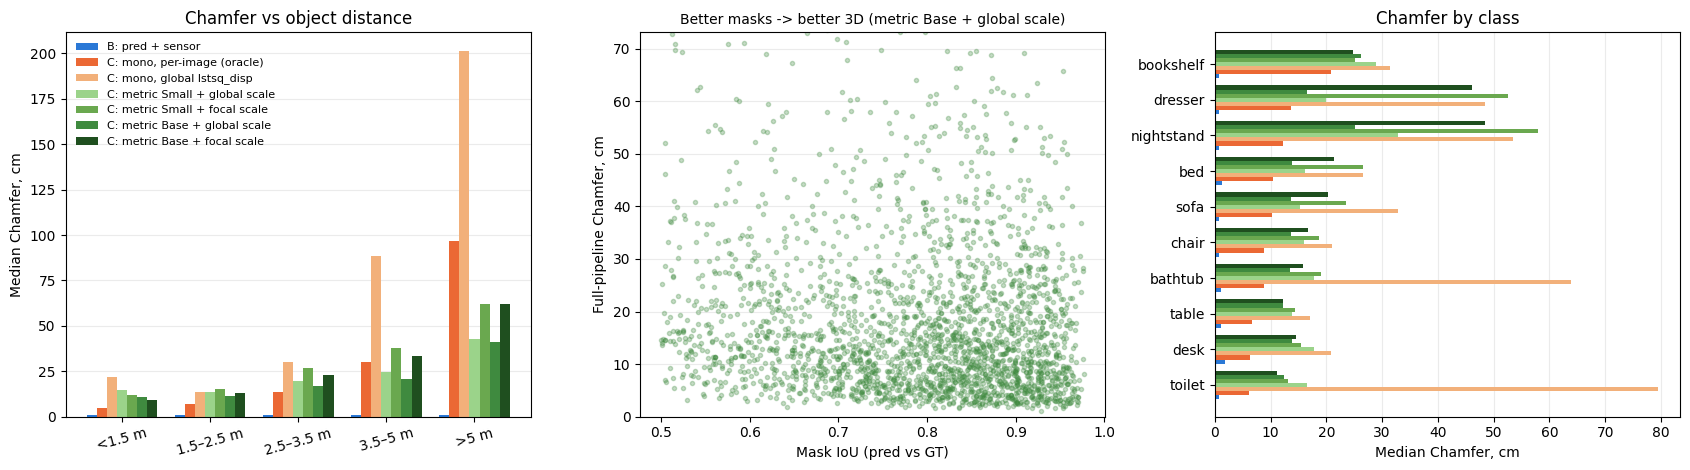

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
series = [("segm", "B: pred + sensor", SENSOR_COLOR)] + \
         [(v, f"C: {LABELS[v]}", VARIANT_COLORS[v]) for v in VARIANTS]
w = 0.8 / len(series)

x = np.arange(len(by_distance))
for i, (prefix, label, color) in enumerate(series):
    axes[0].bar(x + (i - len(series) / 2 + 0.5) * w, by_distance[f"{prefix}_chamfer_cm"],
                w, color=color, label=label)
axes[0].set_xticks(x, by_distance.index, rotation=15)
axes[0].set_ylabel("Median Chamfer, cm"); axes[0].set_title("Chamfer vs object distance")
axes[0].legend(frameon=False, fontsize=8)

show = best_deployable or VARIANTS[-1]
axes[1].scatter(df.mask_iou, df[f"{show}_chamfer_cm"], s=9, c=VARIANT_COLORS[show], alpha=0.3)
axes[1].set_xlabel("Mask IoU (pred vs GT)"); axes[1].set_ylabel("Full-pipeline Chamfer, cm")
axes[1].set_ylim(0, np.nanpercentile(df[f"{show}_chamfer_cm"], 98))
axes[1].set_title(f"Better masks -> better 3D ({LABELS[show]})", fontsize=10)

y = np.arange(len(by_class))
for i, (prefix, label, color) in enumerate(series):
    axes[2].barh(y + (i - len(series) / 2 + 0.5) * w, by_class[f"{prefix}_chamfer_cm"],
                 w, color=color, label=label)
axes[2].set_yticks(y, by_class.index); axes[2].set_xlabel("Median Chamfer, cm")
axes[2].set_title("Chamfer by class")

for ax in axes:
    ax.grid(axis="x" if ax is axes[2] else "y", alpha=0.25)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "pred_masks_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()


---
## Findings for chapter 3

**2483 matched objects on 1100 test images** (of 5669 predictions at
conf >= 0.5; every object has valid clouds in all seven configurations; 90.4 %
correctly classified, median mask IoU 0.812).

**Mask refinement (ablation, full test split, oracle depth):**

| refinement | objects | A thickness | A OBB volume | B Chamfer | B \|vol\| | C Chamfer | C \|vol\| |
|---|---|---|---|---|---|---|---|
| none (v1) | 2772 | 54 cm | 0.83 m³ | 1.80 cm | 29 % | 10.4 cm | 55 % |
| erode 2 px | 2720 | 51 | 0.65 | 1.81 | 32 % | 10.4 | 61 % |
| + discontinuities | 2656 | 43 | 0.39 | 1.27 | 26 % | 10.6 | 58 % |
| + depth outliers | **2621** | **36** | **0.23** | **0.94** | **21 %** | **8.6** | **51 %** |

- The "curtains" were not cosmetic: the median reference cloud was 54 cm
  thick and its OBB volume 0.83 m³ — a chair is neither. Removing boundary
  pixels alone changes little; the depth-discontinuity and per-object outlier
  tests are what remove the streaks (thickness 36 cm, volume 0.23 m³, i.e.
  3.6× smaller). The cost is 5 % of the matched objects (small / distant ones
  dropping below `MIN_POINTS`).
- Segmentation error in 3D shrinks from 1.8 to 0.9 cm Chamfer and volume
  |error| from 29 % to 21 %: most of what a wrong mask boundary used to cost
  was background leaking through it, which the refinement now rejects on
  either side.

**Total 3D error per depth backend (median over objects; all on the same
objects and pixels):**

| configuration | Chamfer | centroid | \|dist err\| | volume (signed) | \|volume\| |
|---|---|---|---|---|---|
| B: pred mask + sensor | **0.85 cm** | 2.7 cm | 0.01 m | −4 % | 19 % |
| C: mono, per-image oracle | 8.3 cm | 13.8 | 0.11 | −38 % | 52 % |
| C: mono, **global** `lstsq_disp` | 21.9 cm | 35.0 | 0.33 | −50 % | 66 % |
| C: **metric Small + global scale** | **15.8 cm** | 27.0 | 0.25 | **−7 %** | 53 % |
| C: metric Small + focal scale | 18.5 cm | 31.8 | 0.31 | −27 % | 59 % |
| C: metric Base + global scale | **13.6 cm** | 22.6 | 0.21 | −12 % | 47 % |
| C: metric Base + focal scale | 16.1 cm | 28.0 | 0.26 | −27 % | 53 % |

- **Segmentation error is almost free in 3D** — once an object is detected
  with IoU >= 0.5, replacing the GT mask with the predicted one moves the
  refined cloud by under 1 cm Chamfer and 3 cm centroid offset.
- **The full pipeline is depth-limited, and the depth backend is the decision
  that matters.** The relative model with its deployable global alignment more
  than doubles the oracle error (21.9 vs 8.3 cm) and collapses volumes
  (−50 %). The metric models with one global scale constant cut that to
  15.8 cm (Small) / 13.6 cm (Base) with **nearly unbiased volumes** (−7 % /
  −12 %) — the price of having no sensor is ×1.6–1.9 over the oracle instead
  of ×2.6. The `focal` variants are worse everywhere except realsense,
  confirming notebook 06: a single constant is the better rule.
- **Metric depth degrades gracefully with distance, relative alignment does
  not:** median Chamfer from <1.5 m to >5 m goes 14.5 → 43 cm (metric Small)
  and 11 → 41 cm (Base) versus 22 → 202 cm (relative global) — even the
  per-image oracle reaches 97 cm beyond 5 m. A metric model carries genuine
  absolute-range knowledge; an affine in disparity space fitted once cannot.
- **Scene type:** the global disparity alignment fails catastrophically in
  bathrooms (toilet 79 cm, bathtub 64 cm — small close-range rooms far from
  the "average" scene the constants describe), where the metric backends stay
  at 12–18 cm. Across classes the metric variants are flat (12–17 cm) except
  nightstand / bookshelf (25–33 cm: small or thin structures).
- **Mask quality still matters monotonically:** metric-Base Chamfer improves
  from 15.7 cm (IoU 0.5–0.7) to 12.1 cm (IoU 0.85–1.0).
- **The real cost of the segmentation model lies outside this table:** at
  conf 0.5 the detector also produces ~3.1k false positives (phantom objects
  in the 3D scene) and misses ~2.5k GT objects entirely — detection quality,
  not mask-boundary quality, is what limits the application.

**Decision:** the web demo runs Mask R-CNN → **metric Depth Anything V2 Small
+ global scale** (same latency as the relative model, 15.8 cm median Chamfer,
volumes within ~10 % on median); the Base model is the drop-in upgrade when
GPU time is available (13.6 cm, 2.6× slower).


---
## Notes and limitations

- **Only matched objects are measured.** FP/FN of the detector never enter the
  table — the application-level consequence (phantom objects, missed objects)
  is quantified by the P/R/F1 tables of `evaluate_predictions.py`
  (Detectron2 std10 test: TP 2561, FP 3108, FN 2527 at conf 0.5).
- **Matching is class-agnostic** (as in the evaluator); `correct_class` marks
  the ~misclassified minority among matched pairs.
- **Common footprint across seven maps.** Every object's clouds use the pixels
  accepted by the refinement in the sensor map *and* all six monocular maps,
  which is stricter than the ablation's single-map protocol (2483 vs 2621
  objects) but makes every column of the summary directly comparable.
  Absolute numbers of the oracle column are therefore slightly different from
  the ablation row with the same settings.
- **Global constants come from validation, never from the test split**
  (sensor-stratified subset, notebook 06); the `focal` variant additionally
  uses each test image's own `fx` — information the demo has for its example
  scenes and assumes (Kinect-like) for uploads.
- **Same cleaning everywhere.** Mask refinement, voxel 2 cm and SOR run
  identically on A, B and every C — `utils/pointcloud.py` is the single
  implementation used by the notebooks and by the demo.
